# Week 1, lab A: Predicting a river's mean flow from what we know about its catchment

## The question

If you knew everything about a river catchment except its flow (its climate, its soils, its geology, its vegetation, its terrain), how well could you guess how much water comes out of it? This is a real question: most rivers in the world have no gauge, and estimating their flow from catchment properties is how hydrologists fill the gaps. It is also the perfect first problem for this course: 671 catchments, 27 numbers describing each one, and one number to predict.

We will use the simplest model there is, a linear regression, and judge it against the simplest baseline there is, a single average. Everything later in the course is a more flexible version of what happens in this notebook.

> **Data card.** *CAMELS catchment attributes (version 2.0).* Source: Addor, Newman, Mizukami and Clark (2017); the attribute files `camels_attributes_v2.0` (DOI 10.5065/D6G73C3Q) are hosted on Zenodo, record 15529996 (record version 1.2, which also carries the CAMELS time series, DOI 10.5065/D6MW2F4D). License: CC BY 4.0; redistribution of subsets is permitted with attribution. What: static attributes (climate, geology, soil, topography, vegetation, hydrologic signatures) for 671 catchments in the contiguous United States; we use the 27 climate, terrain, vegetation, soil and geology attributes of Kratzert et al. (2019) as features and `q_mean`, the mean daily streamflow in mm/day, as the target. Units: in the table after the feature list below. Size: seven text files, 0.6 MB in total, downloaded directly from Zenodo. Coverage: CONUS; climate indices and flow signatures are means over water years 1990–2009 (1 Oct 1989 to 30 Sep 2009), vegetation attributes 2002–2014, soils and geology static. Pre-processing by instructor: none. Citation: Addor, N., Newman, A. J., Mizukami, N., and Clark, M. P. (2017), *Hydrology and Earth System Sciences* 21, 5293–5313; Kratzert, F., Klotz, D., Shalev, G., Klambauer, G., Hochreiter, S., and Nearing, G. (2019), *Hydrology and Earth System Sciences* 23, 5089–5110.


In [1]:
# If this notebook is running on Google Colab, install the one package Colab doesn't ship with.
# This cell comes BEFORE the imports. "%pip" installs into the running kernel.
import sys
if "google.colab" in sys.modules:
    %pip install -q cartopy


In [2]:
# --- Setup: all imports, the seed, plot settings. The same block opens every notebook in this course. ---
import os
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

seed = 42                      # one seed for the whole notebook; re-set it before any cell you re-run
random.seed(seed)
np.random.seed(seed)

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["font.size"] = 12
# Okabe–Ito: eight colorblind-safe colors as the default color cycle
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#E69F00", "#56B4E9", "#009E73", "#F0E442",
                                                     "#0072B2", "#D55E00", "#CC79A7", "#000000"])


## Get the data

> **AI assistant: good use here.** Downloading files and joining tables is boilerplate. An assistant may write cells like the next two for you; you check the shapes and the column names yourself.


In [3]:
data_dir = "data"                       # created next to this notebook; ignored by git
os.makedirs(data_dir, exist_ok=True)

base_url = "https://zenodo.org/records/15529996/files/"
attribute_files = ["camels_clim", "camels_geol", "camels_hydro", "camels_name",
                   "camels_soil", "camels_topo", "camels_vege"]

for name in attribute_files:
    fname = os.path.join(data_dir, name + ".txt")
    if not os.path.exists(fname):       # download once; a hand-placed file is simply used
        print("downloading", name)
        urllib.request.urlretrieve(base_url + name + ".txt?download=1", fname)
print("all seven attribute files are in", data_dir)


all seven attribute files are in data


In [4]:
# The seven files share the column gauge_id. Read each one and join them side by side.
tables = []
for name in attribute_files:
    table = pd.read_csv(os.path.join(data_dir, name + ".txt"), sep=";", dtype={"gauge_id": str})
    tables.append(table.set_index("gauge_id"))
camels = pd.concat(tables, axis=1)      # one row per catchment, every attribute as a column
print(camels.shape)                     # (n_catchments, n_columns)


(671, 59)


In [5]:
# The 27 static attributes used by Kratzert et al. (2019). None is computed from streamflow, which matters:
# anything derived from the target (q_mean, runoff_ratio, baseflow_index, ...) would be cheating.
# (One subtlety: CAMELS' potential evaporation uses a Priestley-Taylor coefficient calibrated per catchment inside
# a rainfall-runoff model (Newman et al., 2015), so pet_mean and aridity are not purely meteorological.)
feature_names = [
    "p_mean", "pet_mean", "aridity", "p_seasonality", "frac_snow",
    "high_prec_freq", "high_prec_dur", "low_prec_freq", "low_prec_dur",
    "elev_mean", "slope_mean", "area_gages2",
    "frac_forest", "lai_max", "lai_diff", "gvf_max", "gvf_diff",
    "soil_depth_pelletier", "soil_depth_statsgo", "soil_porosity", "soil_conductivity",
    "max_water_content", "sand_frac", "silt_frac", "clay_frac",
    "carbonate_rocks_frac", "geol_permeability",
]
target_name = "q_mean"                  # mean daily streamflow, mm/day


The 27 features and their units, from the CAMELS attribute documentation (`camels_attributes_v2.0.pdf`, on the same Zenodo record):

| Group | Feature | Meaning | Unit |
|---|---|---|---|
| climate | `p_mean` | mean daily precipitation | mm/day |
| climate | `pet_mean` | mean daily potential evapotranspiration (Priestley–Taylor) | mm/day |
| climate | `aridity` | `pet_mean` divided by `p_mean` | – |
| climate | `p_seasonality` | seasonality and timing of precipitation (positive: summer peak, negative: winter peak) | – |
| climate | `frac_snow` | fraction of precipitation falling as snow | – |
| climate | `high_prec_freq` | frequency of high-precipitation days (at least five times `p_mean`) | days/year |
| climate | `high_prec_dur` | mean duration of high-precipitation events | days |
| climate | `low_prec_freq` | frequency of dry days (below 1 mm/day) | days/year |
| climate | `low_prec_dur` | mean duration of dry periods | days |
| terrain | `elev_mean` | mean elevation | m |
| terrain | `slope_mean` | mean slope | m/km |
| terrain | `area_gages2` | catchment area | km² |
| vegetation | `frac_forest` | forest fraction | – |
| vegetation | `lai_max` | maximum monthly leaf area index | – |
| vegetation | `lai_diff` | annual range of the monthly leaf area index | – |
| vegetation | `gvf_max` | maximum monthly green vegetation fraction | – |
| vegetation | `gvf_diff` | annual range of the monthly green vegetation fraction | – |
| soil | `soil_depth_pelletier` | depth to bedrock (capped at 50 m) | m |
| soil | `soil_depth_statsgo` | soil depth (top 1.5 m) | m |
| soil | `soil_porosity` | volumetric porosity | – |
| soil | `soil_conductivity` | saturated hydraulic conductivity | cm/hr |
| soil | `max_water_content` | maximum water content of the soil column | m |
| soil | `sand_frac`, `silt_frac`, `clay_frac` | sand, silt and clay fractions of the soil | % |
| geology | `carbonate_rocks_frac` | fraction of the catchment area that is carbonate sedimentary rock | – |
| geology | `geol_permeability` | subsurface permeability | log10 m² |


## Look at the data

Shape, ranges, missing values, one plot. Never skip this step: half of all modelling mistakes are visible here.


In [6]:
print(camels[feature_names + [target_name]].describe().T[["min", "max", "mean"]].round(3))


                          min        max     mean
p_mean                  0.645      8.937    3.258
pet_mean                1.899      4.744    2.787
aridity                 0.220      5.208    1.057
p_seasonality          -1.435      0.922   -0.041
frac_snow               0.000      0.906    0.178
high_prec_freq          7.900     32.700   20.931
high_prec_dur           1.075      2.091    1.350
low_prec_freq         169.900    348.700  254.647
low_prec_dur            2.789     36.513    5.954
elev_mean              10.210   3571.180  759.422
slope_mean              0.822    255.688   46.195
area_gages2             4.030  25791.040  792.618
frac_forest             0.000      1.000    0.640
lai_max                 0.367      5.582    3.216
lai_diff                0.154      4.831    2.449
gvf_max                 0.184      0.916    0.722
gvf_diff                0.029      0.652    0.323
soil_depth_pelletier    0.267     50.000   10.873
soil_depth_statsgo      0.400      1.500    1.293


In [7]:
n_missing = camels[feature_names + [target_name]].isna().sum()
print("missing values per column (only columns with any):")
print(n_missing[n_missing > 0])

catchments = camels.dropna(subset=feature_names + [target_name])
print(f"\n{len(camels)} catchments in the files, {len(catchments)} with every feature and the target present")


missing values per column (only columns with any):
q_mean    1
dtype: int64

671 catchments in the files, 670 with every feature and the target present


Exactly one catchment has a missing value, and it is the target itself (`q_mean`), not a feature; dropping it leaves 670, which is plenty. The ranges tell us the features live on very different scales: catchment area runs from a few square kilometers to tens of thousands, while fractions run from 0 to 1. Keep that in mind for the interpretation step.

Where are these catchments, and how wet are they? A map answers both. The first time cartopy draws coastlines it downloads a small outline file (a one-off download outside our data cell).


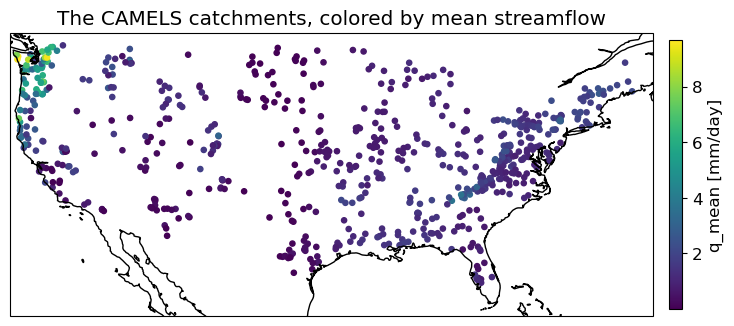

In [8]:
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
ax.coastlines()
points = ax.scatter(catchments["gauge_lon"], catchments["gauge_lat"], c=catchments[target_name],
                    cmap="viridis", s=14, transform=ccrs.PlateCarree())
fig.colorbar(points, ax=ax, label="q_mean [mm/day]", shrink=0.7, pad=0.02)
ax.set_title("The CAMELS catchments, colored by mean streamflow")
plt.show()


Catchment gauges cover the contiguous United States. The wettest catchments (yellow-green, above 5 mm/day) are all on the Pacific Northwest coast; the Appalachians and the Northeast form a moderate secondary maximum (blue-green, 1–3 mm/day); the driest (dark purple, below 1 mm/day) are the Great Plains and the Southwest. Flow varies by a factor of more than a hundred across the country, which already suggests that climate will dominate the prediction.


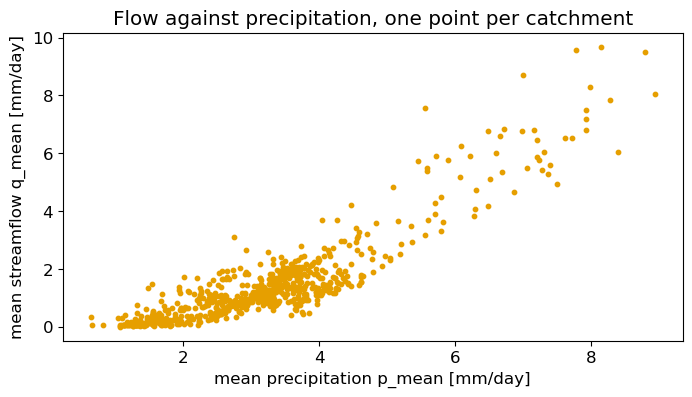

In [9]:
fig, ax = plt.subplots()
ax.scatter(catchments["p_mean"], catchments[target_name], s=10)
ax.set_xlabel("mean precipitation p_mean [mm/day]")
ax.set_ylabel("mean streamflow q_mean [mm/day]")
ax.set_title("Flow against precipitation, one point per catchment")
plt.show()


Flow rises with precipitation, roughly linearly, but with a wide spread: two catchments with the same rainfall can differ by a factor of two or three in flow. The rest of the attributes exist to explain that spread.

## Split, then baseline

We hold out a quarter of the catchments as a test set before fitting anything, so that every number we report is measured on catchments the model never saw.

The **baseline** is the simplest possible predictor: predict the training-set average for every catchment. Any model that cannot beat this is not learning anything.


In [10]:
X = catchments[feature_names].values                 # (n_catchments, 27)
y = catchments[target_name].values                   # (n_catchments,)
print(X.shape, y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)
print(X_train.shape, X_test.shape)


(670, 27) (670,)
(502, 27) (168, 27)


In [11]:
def rmse(y: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y - y_pred) ** 2)))

baseline_pred = np.full_like(y_test, y_train.mean())              # the same number for every test catchment
rmse_baseline = rmse(y_test, baseline_pred)
print(f"baseline (predict the mean, {y_train.mean():.2f} mm/day):  test RMSE = {rmse_baseline:.3f} mm/day")


baseline (predict the mean, 1.48 mm/day):  test RMSE = 1.523 mm/day


## The method: linear regression, with one feature and then with 27

> **Write this yourself.** From here to the evaluation is the modeling core of the week: the cells that the homework asks you to write yourself, without an assistant. In the lab they are worked for you; read them as if you were about to write them.

First the model from the core notebook: flow as a straight-line function of precipitation alone.


In [12]:
p_mean_index = feature_names.index("p_mean")

model_1 = LinearRegression()
model_1.fit(X_train[:, [p_mean_index]], y_train)                   # [[index]] keeps X two-dimensional: (n, 1)

rmse_1 = rmse(y_test, model_1.predict(X_test[:, [p_mean_index]]))
print(f"one feature (p_mean):   test RMSE = {rmse_1:.3f} mm/day")
print(f"slope = {model_1.coef_[0]:.3f} mm flow per mm precipitation,  intercept = {model_1.intercept_:+.3f} mm/day")


one feature (p_mean):   test RMSE = 0.699 mm/day
slope = 0.968 mm flow per mm precipitation,  intercept = -1.670 mm/day


Now all 27 attributes at once. The model is still a straight line, just in 27 dimensions: $\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_{27} x_{27} + b$.

One preparation step: the features live on wildly different scales (area in km², fractions in 0–1), so we **standardize** them, subtracting each feature's mean and dividing by its standard deviation, computed on the **training set only**. Linear regression would fit the same line without it, but the coefficients would be incomparable: a coefficient per km² means nothing next to a coefficient per unit fraction. After standardizing, every coefficient answers the same question: how much does the prediction change when this feature moves by one standard deviation?


In [13]:
scaler = StandardScaler()
scaler.fit(X_train)                                  # means and standard deviations from the training set only
X_train_std = scaler.transform(X_train)              # (n_train, 27), each column now has mean 0 and std 1
X_test_std = scaler.transform(X_test)                # the SAME transformation applied to the test set

model_27 = LinearRegression()
model_27.fit(X_train_std, y_train)

rmse_27 = rmse(y_test, model_27.predict(X_test_std))
print(f"27 features:   test RMSE = {rmse_27:.3f} mm/day")


27 features:   test RMSE = 0.397 mm/day


## Evaluation

Three numbers side by side, and a picture of how the predictions compare with the truth.


In [14]:
print(f"baseline (mean):      {rmse_baseline:.3f} mm/day")
print(f"one feature (p_mean): {rmse_1:.3f} mm/day   ({100 * (1 - rmse_1 / rmse_baseline):.0f}% lower than baseline)")
print(f"27 features:          {rmse_27:.3f} mm/day   ({100 * (1 - rmse_27 / rmse_baseline):.0f}% lower than baseline)")

y_test_pred = model_27.predict(X_test_std)
print(f"\n{int((y_test_pred < 0).sum())} of {len(y_test_pred)} test predictions are below zero (lowest: {y_test_pred.min():.2f} mm/day)")


baseline (mean):      1.523 mm/day
one feature (p_mean): 0.699 mm/day   (54% lower than baseline)
27 features:          0.397 mm/day   (74% lower than baseline)

7 of 168 test predictions are below zero (lowest: -0.26 mm/day)


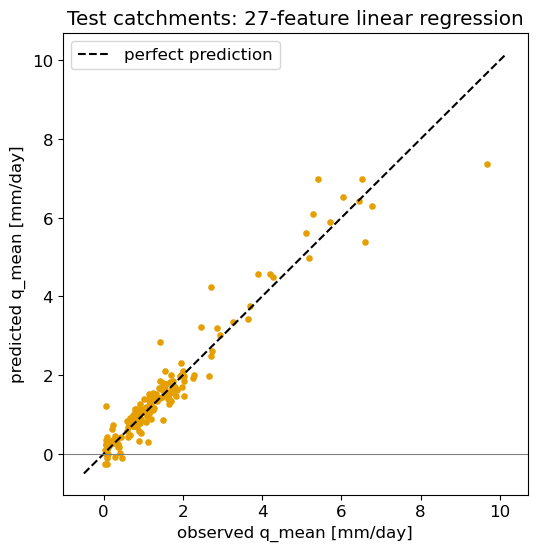

In [15]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_test_pred, s=14)
limits = [-0.5, max(y_test.max(), y_test_pred.max()) * 1.05]
ax.plot(limits, limits, "k--", label="perfect prediction")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("observed q_mean [mm/day]")
ax.set_ylabel("predicted q_mean [mm/day]")
ax.set_title("Test catchments: 27-feature linear regression")
ax.legend()
plt.show()


Points hugging the dashed 1:1 line are catchments predicted well. The spread widens for the wettest catchments (the wettest, the Queets River in Washington at 9.7 mm/day, is predicted at about 7.4), and a few predictions (the print above counts them) fall below zero flow, something a straight line cannot know is impossible. Both are limitations of a linear model that later weeks address.

Which attributes carry the prediction? With standardized features, the size of each coefficient says how much a one-standard-deviation change in that attribute moves the predicted flow.


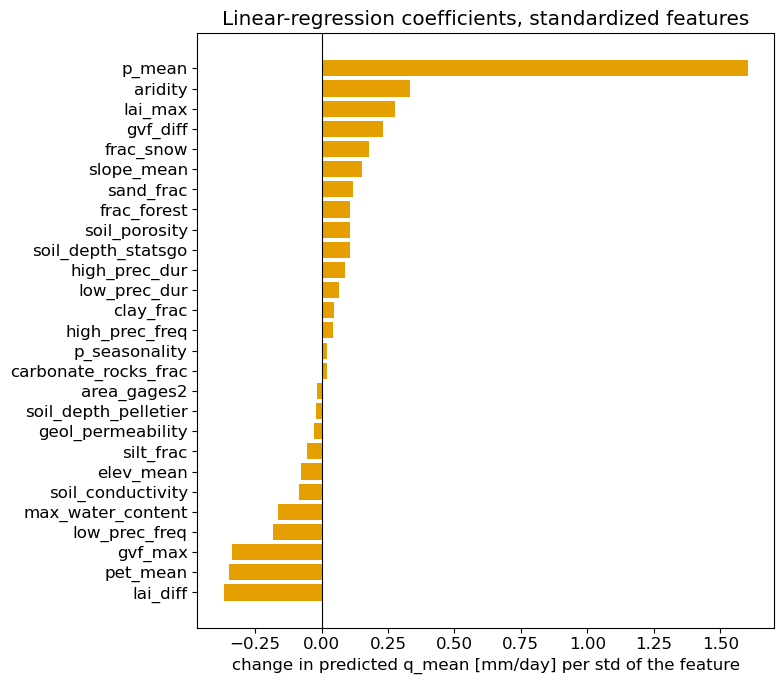

largest positive: {'lai_max': 0.276, 'aridity': 0.334, 'p_mean': 1.604}
largest negative: {'lai_diff': -0.368, 'pet_mean': -0.349, 'gvf_max': -0.336}


In [16]:
coefficients = pd.Series(model_27.coef_, index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coefficients.index, coefficients.values)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("change in predicted q_mean [mm/day] per std of the feature")
ax.set_title("Linear-regression coefficients, standardized features")
fig.tight_layout()
plt.show()

print("largest positive:", coefficients.tail(3).round(3).to_dict())
print("largest negative:", coefficients.head(3).round(3).to_dict())


`p_mean` dominates: about +1.6 mm/day of predicted flow per standard deviation of precipitation, five times any other coefficient. Next come aridity (+0.33), `lai_max` (+0.28) and `gvf_diff` (+0.23); the largest negatives are `lai_diff` (−0.37), `pet_mean` (−0.35) and `gvf_max` (−0.34); geology and most soil attributes sit near zero.

Only `p_mean` and `pet_mean` carry the signs a hydrologist would predict: more rain, more flow; more evaporative demand, less flow. The others come in near-duplicate pairs. Aridity *is* `pet_mean` divided by `p_mean`, so with both parents in the model its coefficient only patches the curvature a straight line cannot express; and `lai_max` and `lai_diff` are 0.94-correlated, as are the two `gvf` attributes. When two features are near-copies, a linear model can split their shared effect between them arbitrarily, often as a large positive and a large negative that cancel. Large opposite-signed pairs are the signature of **collinearity**; do not read them as physics. Week 2's Lasso removes most of them.

## Interpretation

Write this part in your own words when you do the homework; here is ours.

The single-feature model already removes most of the baseline's error: knowing how much it rains tells you most of what there is to know about how much water leaves a catchment, which is the water balance at work. Adding the other 26 attributes helps further, but by a smaller margin, and the coefficient plot shows why: precipitation does most of the work, potential evaporation adds a little, the remaining large coefficients are collinear pairs that largely cancel, and most soil and geology attributes contribute little *in a linear model*.

That last qualifier matters. It may be that soils and geology do not control mean flow, or it may be that their effect is nonlinear or interacts with climate in ways a straight line cannot express. Week 2 asks whether a more flexible model helps and Week 5 asks the same of a neural network; the honest answer to "does the fancy model win?" always comes back to this notebook's baseline and this notebook's test RMSE.

Two caveats. The test catchments were drawn at random from the whole country, so they are neighbors of training catchments; Week 3 shows that this makes the test error optimistic. And `q_mean` is a long-term average: the model says nothing about floods, droughts or seasons, which need the time series of Week 9.

> **Earth-science aside.** The one-feature slope, 0.97 mm of flow per mm of precipitation, is *not* the runoff ratio Q/P, which averages 0.39 across CAMELS. The slope is how much mean flow rises per extra mm/day of precipitation *across* catchments. With an intercept of −1.7 mm/day the line implies a runoff ratio of 0.97 − 1.67/P, which rises with P: in the data, the driest fifth of catchments turn 18 % of their precipitation into flow and the wettest fifth 63 %, because wet catchments lose a smaller share to evapotranspiration. (The line even implies negative flow for the driest catchments, one more thing a straight line cannot know is impossible.) This is the energy-limited limb of the Budyko framework, which Week 2's lab returns to.

## Exercises

Labs are graded on completion: run every cell and attempt each exercise, leaving your result in the cell provided. Keep `random_state=seed` in any split you make, so that your numbers are comparable with a classmate's; solutions to the lab exercises are released at the homework deadline.

> **Exercise.** Drop `p_mean` from the feature list and refit the 27-feature model (now 26). How much test RMSE do you lose? Is precipitation irreplaceable, or do the other climate attributes stand in for it?


In [17]:
# Exercise 1: work here
np.random.seed(seed)


*One sentence on what you found:*


> **Exercise.** Predict `runoff_ratio` (flow divided by precipitation; it is already a column of `catchments`) instead of `q_mean`, with the same 27 features. Which attributes matter now, and does precipitation still dominate?


In [18]:
# Exercise 2: work here
np.random.seed(seed)


*One sentence on what you found:*


> **Exercise.** Fit the 27-feature model to the logarithm of flow, `np.log(y + 0.01)` (one catchment has essentially zero flow, and the logarithm of zero is not a number), and convert the predictions back with `np.exp(...) - 0.01` before computing the test RMSE in mm/day. Does the log transform fix the negative predictions, and does the RMSE improve?


In [19]:
# Exercise 3: work here
np.random.seed(seed)


*One sentence on what you found:*
